## Dust Compound Mask - IRAC4 & MIRIf21

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import astropy.units as u
import os
import shutil
from astropy.io import fits # importing fits 
from astropy.utils.data import download_file # simple method of downloading FITS file 
from astropy.visualization import astropy_mpl_style # resource for organized plots
from astropy.visualization import ZScaleInterval, MinMaxInterval, AsinhStretch, LogStretch, ImageNormalize # quality image display/visualization
from astropy.wcs import WCS #coordinate conversion
from regions import Regions # import astropy region class
from regions import CompoundSkyRegion


In [ ]:
from astropy.io import fits 
from astropy.wcs import WCS

with fits.open(r"C:/Users/Lamat/OneDrive - The Ohio State University/Lamat NGC 253 Environment Mask/Plotting Regions/ngc0253_miri_lv3_f2100w_i2d_align.fits") as hdul:
    data = None
    header = None
    for hdu in hdul:
        if hdu.data is not None and hdu.header.get("NAXIS",0) >= 2:
            data = hdu.data 
            header = hdu.header 
            print(f"Found data in extension: {hdu.name or hdul.index(hdu)}")
            break 
            
        if data is None:
            print("None")
            
wcs = WCS(header) #see https://astronomy.stackexchange.com/questions/51673/how-to-slice-wcs-in-a-fits-file
        # access region file via parsing & converting data from wcs to pixel. the 0 is for the FIRST region plotted
        # for i in regionfile??? what i want to do is for each region in the regionfile, plot each region if an index exists for that region

Found data in extension: HA6562_FLUX
Found data in extension: HA6562_FLUX


C:\Users\Lamat\AppData\Local\Programs\Python\Python314\Lib\site-packages\regions\shapes\polygon.py:225: UserWarning: Setting the 'color' property will override the edgecolor or facecolor properties.
  return Polygon(xy=xy, **mpl_kwargs)


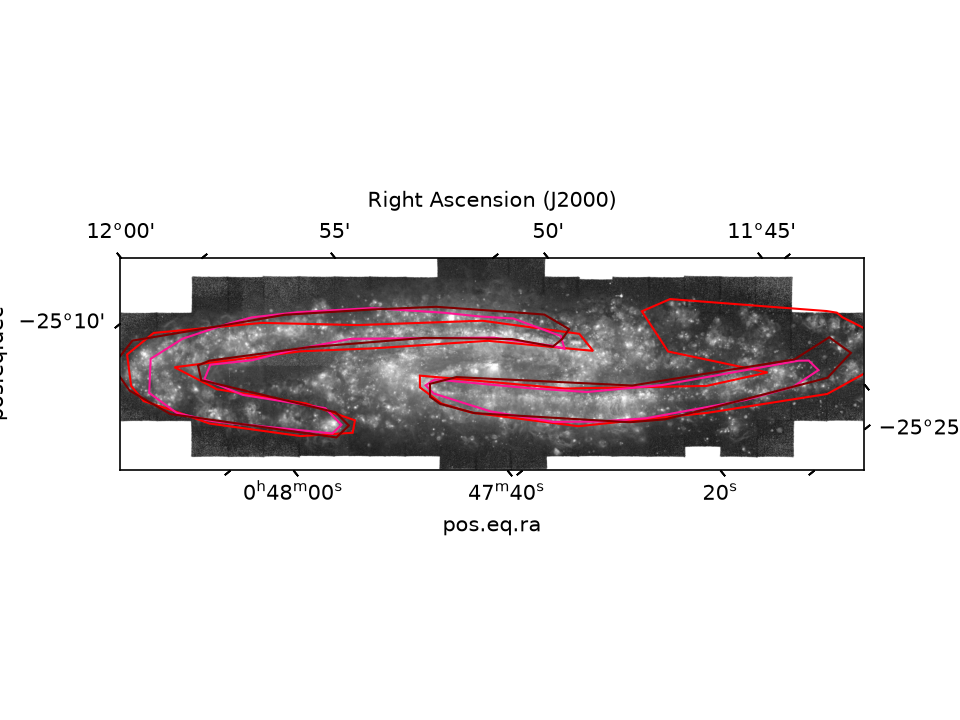

In [4]:
%matplotlib widget

mirif21_disk_regionfile = r"C:\Users\Lamat\OneDrive - The Ohio State University/Lamat NGC 253 Environment Mask/Plotting Regions/disk_mirif21_regionfile_jwst_adjusted713026.reg"
irac4_disk_regionfile = r"C:\Users\Lamat\OneDrive - The Ohio State University/Lamat NGC 253 Environment Mask/Plotting Regions/disk_irac_regionfile_adjusted71326_spitzer.reg"

mirif21_disk_region1 = Regions.read(mirif21_disk_regionfile)[0] 
irac4_disk_region2 = Regions.read(irac4_disk_regionfile)[0]


comp_diskregion = mirif21_disk_region1 & irac4_disk_region2
dust_disk = comp_diskregion.to_pixel(wcs)

comp_diskregion2 = mirif21_disk_region1 | irac4_disk_region2
dust_disk2 = comp_diskregion2.to_pixel(wcs)

disk_mask = dust_disk.to_mask(mode='center') #https://github.com/astropy/regions/issues/433, this basically helped me understand that it's hard to actually create a new .reg file for a comp region
disk_mask2 = dust_disk2.to_mask(mode='center')


mirif21_spiralarms_regionfile = r"C:\Users\Lamat\OneDrive - The Ohio State University/Lamat NGC 253 Environment Mask/Plotting Regions/spiralarms_mirif21_regionfile_jwst.reg"
irac4_spiralarms_regionfile = r"C:\Users\Lamat\OneDrive - The Ohio State University/Lamat NGC 253 Environment Mask/Plotting Regions/spiralarms_irac4_regionfile_spitzer.reg"

mirif21_spiralarms_region1 = Regions.read(mirif21_spiralarms_regionfile)[0]
mirif21_spiralarms_region11 = Regions.read(mirif21_spiralarms_regionfile)[1]
irac4_spiralarms_region2 = Regions.read(irac4_spiralarms_regionfile)[0]
irac4_spiralarms_region22 = Regions.read(irac4_spiralarms_regionfile)[1]

comp_spiralregion1 = mirif21_spiralarms_region1 & irac4_spiralarms_region2 
comp_spiralregion2 = mirif21_spiralarms_region11 & irac4_spiralarms_region22
comp_spiralregion3 = mirif21_spiralarms_region1 | irac4_spiralarms_region2 
comp_spiralregion4 = mirif21_spiralarms_region11 | irac4_spiralarms_region22


dust_spiral1 = comp_spiralregion1.to_pixel(wcs)
dust_spiral2 = comp_spiralregion2.to_pixel(wcs)
dust_spiral3 = comp_spiralregion3.to_pixel(wcs)
dust_spiral4 = comp_spiralregion4.to_pixel(wcs)

spiral_mask1 = dust_spiral1.to_mask(mode='center')
spiral_mask2 = dust_spiral2.to_mask(mode='center')
spiral_mask3 = dust_spiral3.to_mask(mode='center')
spiral_mask4 = dust_spiral4.to_mask(mode='center')




mirif21_ring_regionfile = r"C:\Users\Lamat\OneDrive - The Ohio State University/Lamat NGC 253 Environment Mask/Plotting Regions/ring_mirif21_regionfile_jwst_thicker.reg"
irac4_ring_regionfile = r"C:\Users\Lamat\OneDrive - The Ohio State University/Lamat NGC 253 Environment Mask/Plotting Regions/ring_irac_regionfile_spitzer.reg"

mirif21_region1 = Regions.read(mirif21_ring_regionfile)[0]
mirif21_region11 = Regions.read(mirif21_ring_regionfile)[1]
irac4_ring_region2 = Regions.read(irac4_ring_regionfile)[0]
irac4_ring_region22 = Regions.read(irac4_ring_regionfile)[1]

comp_ringregion1 = mirif21_ring_region1 & irac4_ring_region2 
comp_ringregion2 = mirif21_ring_region11 & irac4_ring_region22
comp_ringregion3 = mirif21_ring_region1 | irac4_ring_region2 
comp_ringregion4 = mirif21_ring_region11 | irac4_ring_region22


dust_ring1 = comp_ringregion1.to_pixel(wcs)
dust_ring2 = comp_ringregion2.to_pixel(wcs)
dust_ring3 = comp_ringregion3.to_pixel(wcs)
dust_ring4 = comp_ringregion4.to_pixel(wcs)

ring_mask1 = dust_ring1.to_mask(mode='center')
ring_mask2 = dust_ring2.to_mask(mode='center')
ring_mask3 = dust_ring3.to_mask(mode='center')
ring_mask4 = dust_ring4.to_mask(mode='center')

outer = ring_mask1.to_image(data.shape)
inner = ring_mask2.to_image(data.shape)

outer1 = ring_mask3.to_image(data.shape)
inner1 = ring_mask4.to_image(data.shape)

annulus_mask = (outer > 0) & (inner == 0)
annulus_mask = (outer1 > 0) & (inner1 == 0)


mirif21_bar_regionfile = r"C:\Users\Lamat\OneDrive - The Ohio State University/Lamat NGC 253 Environment Mask/Plotting Regions/bar_f21miri_regionfile_jwst_twoboxes_updated.reg"
irac4_bar_regionfile = r"C:\Users\Lamat\OneDrive - The Ohio State University/Lamat NGC 253 Environment Mask/Plotting Regions/bar_irac4_regionfile_spitzer_twoboxes.reg"

mirif21_bar_region1 = Regions.read(mirif21_bar_regionfile)[0]
mirif21_bar_region11 = Regions.read(mirif21_bar_regionfile)[1]
irac4_bar_region2 = Regions.read(irac4_bar_regionfile)[0]
irac4_bar_region22 = Regions.read(irac4_bar_regionfile)[1]

comp_barregion1 = mirif21_bar_region1 & irac4_bar_region2 
comp_barregion2 = mirif21_bar_region11 & irac4_bar_region22
comp_barregion3 = mirif21_bar_region1 | irac4_bar_region2 
comp_barregion4 = mirif21_bar_region11 | irac4_bar_region22

dust_bar1 = comp_barregion1.to_pixel(wcs)
dust_bar2 = comp_barregion2.to_pixel(wcs)
dust_bar3 = comp_barregion3.to_pixel(wcs)
dust_bar4 = comp_barregion4.to_pixel(wcs)

bar_mask1 = dust_bar1.to_mask(mode='center')
bar_mask2 = dust_bar2.to_mask(mode='center')
bar_mask3 = dust_bar3.to_mask(mode='center')
bar_mask4 = dust_bar4.to_mask(mode='center')



irac4_center_regionfile = r"C:\Users\Lamat\OneDrive - The Ohio State University/Lamat NGC 253 Environment Mask/Plotting Regions/center_irac4_regionfile_spitzer.reg"
irac4_center_region = Regions.read(irac4_center_regionfile)[0]

irac4_center = irac4_center_region.to_pixel(wcs)

center_mask = irac4_center.to_mask(mode='center')


mask_array = np.where((ring_mask1.to_image(data.shape)).astype(int) == 1,10000, 0)

mask_array = np.where((ring_mask2.to_image(data.shape)).astype(int) == 1, 0, mask_array)

mask_array = np.where((disk_mask.to_image(data.shape)).astype(int) == 1, mask_array+1, 0) #disk, where the disk mask=1, assign pixel value 1 to the overall mask array

mask_array = np.where((spiral_mask1.to_image(data.shape)).astype(int) == 1, mask_array+100000, mask_array) #spiral arm 1

mask_array = np.where((spiral_mask2.to_image(data.shape)).astype(int) == 1, mask_array+100000, mask_array) # spiral arm 2

mask_array = np.where((bar_mask1.to_image(data.shape)).astype(int) == 1, mask_array+100, mask_array)

mask_array = np.where((bar_mask2.to_image(data.shape)).astype(int) == 1, mask_array+100, mask_array)

mask_array = np.where((center_mask.to_image(data.shape)).astype(int) == 1, mask_array+1000000, mask_array)



mask_array = np.where((ring_mask3.to_image(data.shape)).astype(int) == 1,10000, 0)

mask_array = np.where((ring_mask4.to_image(data.shape)).astype(int) == 1, 0, mask_array)

mask_array = np.where((disk_mask2.to_image(data.shape)).astype(int) == 1, mask_array+1, 0) #disk, where the disk mask=1, assign pixel value 1 to the overall mask array

mask_array = np.where((spiral_mask3.to_image(data.shape)).astype(int) == 1, mask_array+100000, mask_array) #spiral arm 1

mask_array = np.where((spiral_mask4.to_image(data.shape)).astype(int) == 1, mask_array+100000, mask_array) # spiral arm 2

mask_array = np.where((bar_mask3.to_image(data.shape)).astype(int) == 1, mask_array+100, mask_array)

mask_array = np.where((bar_mask4.to_image(data.shape)).astype(int) == 1, mask_array+100, mask_array)




plt.imshow(mask_array, norm='log')
plt.colorbar()
plt.title('Dust Mask- IRAC4/MIRIf21')
plt.savefig('Dust Mask_IRAC4/MIRIf21')
plt.show()





In [ ]:
hdu = fits.PrimaryHDU(data=mask_array)
print(hdu)
#hdu.header = header
#wcs2 = WCS(header)
#print(wcs2)
hdu.writeto('irac4_mirif21_dust_mask.fits', overwrite=True)